# Phase 5 — Closed Itemsets & Closed Association Rules with COFI
**Student:** Jeswin Tobias J &nbsp;|&nbsp; **Roll No:** CS23I1013
**Input:** `outputs/transactions.txt` — 52,416 transactions, 35 items (Phase 1)

### COFI-tree mining
1. Build an **FP-tree** (items in descending support, header table with node links) — 2 scans.
2. For each frequent item *i*, **least frequent first**, build one small **Co-Occurrence Frequent-Item tree** from the FP-tree paths above *i*. It only holds items that are more frequent than *i* and frequent *together with* *i*. Each node stores a count and a **participation** counter.
3. Mine it: branch count = count − participation; every sub-pattern of the branch (plus *i*) receives that count; then participation is increased along the branch so nothing is counted twice.
4. Discard that tree before building the next → **only one COFI-tree in memory at a time**, no recursive conditional trees (unlike FP-Growth).

### From frequent to closed
- **Closed (CFI):** no immediate superset has the same support. **Maximal (MFI):** no immediate superset is frequent. MFI ⊆ CFI ⊆ FI.
- Strategy: mine all frequent itemsets (here with COFI), then keep the closed ones. CFIs are **lossless** (every frequent itemset's support can be recovered); MFIs are not.
- **Closed association rules** = Min-Max bases: **exact** rules *G → closure(G) \ G* (confidence 100 %) and **approximate** rules *G → Z \ G* between a minimal generator *G* and a larger closed set *Z*. Transitively reduced (Z covers closure(G)), they form a non-redundant summary from which, in theory, the full rule set can be derived. Here we verify the property we can check directly: every rule's support and confidence is recomputable from the CFIs.

### Parameters (assumed & stated) — same as DIC for a direct comparison
min support **10 %**, min confidence **70 %**.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, time
from collections import Counter
from src.common import *
from src.cofi import cofi, closed_and_maximal, closure, minimal_generators, minmax_rules
from src.arm import encode, dic, apriori_counts, generate_rules, drop_redundant

set_style(); header()
pd.set_option('display.width', 180, 'display.max_colwidth', 90)
MIN_SUP, MIN_CONF = 0.10, 0.70
fmt = lambda s: '{' + ', '.join(sorted(s)) + '}'

Jeswin Tobias J | CS23I1013 | ASBD Hackathon — Tetouan Power Consumption


## 1. Run COFI on the Tetouan transactions

In [2]:
T = [line.split(',') for line in (OUTPUTS / 'transactions.txt').read_text().splitlines()]
N = len(T)
freq, stats, cofi_sizes = cofi(T, MIN_SUP)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in stats.items()})

# Correctness: identical to Apriori / DIC (Phase 3)
X, items = encode(T)
f_ap, _ = apriori_counts(X, MIN_SUP)
print('Same itemsets and counts as Apriori:', freq == {frozenset(items[i] for i in s): c for s, c in f_ap.items()})

{'time_s': 0.063, 'frequent': 768, 'fp_tree_nodes': 14275, 'subpatterns_enumerated': 118045, 'max_cofi_nodes': 429, 'total_cofi_nodes': 4826}


Same itemsets and counts as Apriori: True


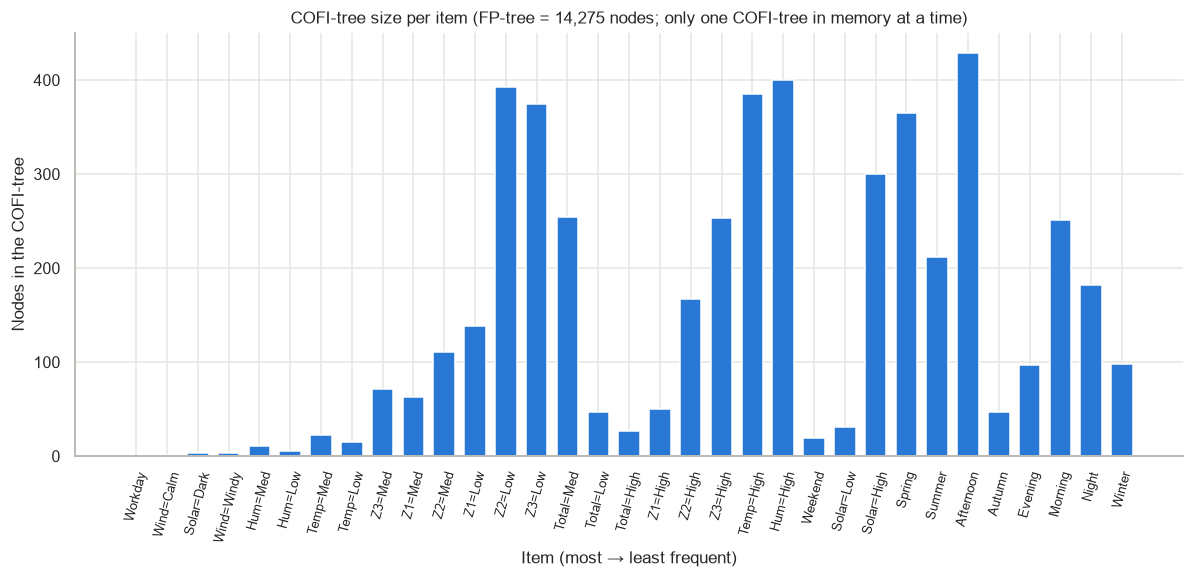

Largest COFI-tree: Afternoon (429 nodes) = 3.0% of the FP-tree
Empty COFI-tree: ['Workday'] (most frequent item: no item lies above it in the FP-tree)


In [3]:
# COFI-tree size per item (items in descending global support = FP-tree order)
sup1 = pd.Series({next(iter(k)): v / N for k, v in freq.items() if len(k) == 1}).sort_values(ascending=False)
sizes = pd.Series(cofi_sizes).reindex(sup1.index)
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(sizes.index, sizes.values, color=CAT[0], width=0.7)
ax.set(title=f'COFI-tree size per item (FP-tree = {stats["fp_tree_nodes"]:,} nodes; only one COFI-tree in memory at a time)',
       ylabel='Nodes in the COFI-tree', xlabel='Item (most → least frequent)')
ax.tick_params(axis='x', rotation=75, labelsize=8.5)
save_fig('31_cofi_tree_sizes'); plt.show()
print(f'Largest COFI-tree: {sizes.idxmax()} ({sizes.max()} nodes) = {sizes.max()/stats["fp_tree_nodes"]:.1%} of the FP-tree')
print('Empty COFI-tree:', sizes[sizes == 0].index.tolist(), '(most frequent item: no item lies above it in the FP-tree)')

**Inferences:**
- COFI finds the same **768 frequent itemsets with identical counts** as Apriori and DIC, reading the raw data only **once**: it is first merged into 3,986 distinct weighted transactions, and the support count and FP-tree are built from those.
- The FP-tree compresses 52,416 transactions into **14,275 nodes**; the largest COFI-tree (*Afternoon*) has only **429 nodes (3 % of the FP-tree)**, and only one exists at a time → very small mining memory.
- COFI-trees are largest for mid-frequency items (time-of-day, season, zone levels) that co-occur with many others. The most frequent item (*Workday*) has an empty tree by design.

## 2. Closed (CFI) and maximal (MFI) itemsets

In [4]:
closed, maximal = closed_and_maximal(freq)
by_size = pd.DataFrame({'FI': Counter(len(k) for k in freq), 'CFI': Counter(len(k) for k in closed),
                        'MFI': Counter(len(k) for k in maximal)}).fillna(0).astype(int).sort_index()
by_size.loc['total'] = by_size.sum()
print(f'FI = {len(freq)} | CFI = {len(closed)} ({len(closed)/len(freq):.1%}) | MFI = {len(maximal)} ({len(maximal)/len(freq):.1%})')

# Lossless check: every FI support = max support of its closed supersets
rebuilt = {Xs: max(c for C, c in closed.items() if Xs <= C) for Xs in freq}
print('All 768 supports recovered from CFIs alone:', rebuilt == freq)
by_size.T

FI = 768 | CFI = 753 (98.0%) | MFI = 198 (25.8%)
All 768 supports recovered from CFIs alone: True


,1,2,3,4,5,6,total
FI,33,224,281,172,52,6,768
CFI,33,224,278,162,50,6,753
MFI,0,60,66,46,20,6,198


In [5]:
# Export the actual closed frequent itemsets (with their minimal generators)
gens_of = {}
for G in minimal_generators(freq, N):
    gens_of.setdefault(closure(G, closed, freq), []).append(G)
cfi_table = pd.DataFrame([{'closed_itemset': fmt(C), 'size': len(C), 'count': c, 'support': c / N,
                           'maximal': C in maximal, 'minimal_generators': ' | '.join(sorted(fmt(g) for g in gens_of.get(C, [])))}
                          for C, c in closed.items()]).sort_values(['size', 'count'], ascending=[False, False]).reset_index(drop=True)
cfi_table.to_csv(OUTPUTS / 'cofi_closed_itemsets.csv', index=False)
print(f'Saved outputs/cofi_closed_itemsets.csv: {len(cfi_table)} closed itemsets ({cfi_table.maximal.sum()} also maximal)')
print('\nLongest closed itemsets:')
display(cfi_table.head(8).round(3))
print('Highest-support closed itemsets of size >= 3:')
cfi_table[cfi_table['size'] >= 3].sort_values('count', ascending=False).head(8).round(3)

Saved outputs/cofi_closed_itemsets.csv: 753 closed itemsets (198 also maximal)

Longest closed itemsets:


,closed_itemset,size,count,support,maximal,minimal_generators
0,"{Night, Solar=Dark, Total=Low, Wind=Calm, Z1=Low, Z2=Low}",6,6270,0.120,True,"{Night, Solar=Dark, Total=Low, Wind=Calm, Z1=Low, Z2=Low}"
1,"{Night, Solar=Dark, Total=Low, Workday, Z1=Low, Z2=Low}",6,6027,0.115,True,"{Night, Solar=Dark, Total=Low, Workday, Z1=Low, Z2=Low}"
2,"{Solar=Dark, Total=Low, Wind=Calm, Workday, Z1=Low, Z2=Low}",6,5470,0.104,True,"{Solar=Dark, Total=Low, Wind=Calm, Workday, Z1=Low, Z2=Low}"
3,"{Solar=Dark, Temp=Low, Total=Low, Wind=Calm, Z1=Low, Z2=Low}",6,5428,0.104,True,"{Solar=Dark, Temp=Low, Total=Low, Wind=Calm, Z1=Low, Z2=Low}"
4,"{Summer, Temp=High, Total=High, Z1=High, Z2=High, Z3=High}",6,5411,0.103,True,"{Summer, Temp=High, Z1=High, Z2=High, Z3=High}"
5,"{Evening, Total=High, Workday, Z1=High, Z2=High, Z3=High}",6,5376,0.103,True,"{Evening, Workday, Z1=High, Z2=High, Z3=High}"
6,"{Night, Solar=Dark, Total=Low, Z1=Low, Z2=Low}",5,8676,0.166,False,"{Night, Solar=Dark, Total=Low, Z1=Low, Z2=Low}"
7,"{Solar=Dark, Total=Low, Wind=Calm, Z1=Low, Z2=Low}",5,7823,0.149,False,"{Solar=Dark, Total=Low, Wind=Calm, Z1=Low, Z2=Low}"


Highest-support closed itemsets of size >= 3:


,closed_itemset,size,count,support,maximal,minimal_generators
218,"{Total=Low, Z1=Low, Z2=Low}",3,14229,0.271,False,"{Total=Low, Z1=Low, Z2=Low}"
219,"{Total=High, Z1=High, Z2=High}",3,12923,0.247,False,"{Total=High, Z1=High, Z2=High}"
220,"{Total=High, Z1=High, Z3=High}",3,12722,0.243,False,"{Total=High, Z1=High, Z3=High}"
221,"{Solar=Dark, Total=Low, Z1=Low}",3,11924,0.227,False,"{Solar=Dark, Total=Low, Z1=Low}"
222,"{Total=Low, Z1=Low, Z3=Low}",3,11660,0.222,False,"{Total=Low, Z1=Low, Z3=Low}"
223,"{Total=Low, Wind=Calm, Z1=Low}",3,11583,0.221,False,"{Total=Low, Wind=Calm, Z1=Low}"
224,"{Solar=Dark, Wind=Calm, Workday}",3,11547,0.220,False,"{Solar=Dark, Wind=Calm, Workday}"
225,"{Solar=Dark, Z1=Low, Z2=Low}",3,11184,0.213,False,"{Solar=Dark, Z1=Low, Z2=Low}"


In [6]:
# Which frequent itemsets are NOT closed, and their closures
nc = sorted((Xs for Xs in freq if Xs not in closed), key=lambda s: -freq[s])
pd.DataFrame({'not-closed itemset': [fmt(s) for s in nc], 'support': [freq[s] / N for s in nc],
              'closure adds': [fmt(closure(s, closed, freq) - s) for s in nc]}).round(3)

,not-closed itemset,support,closure adds
0,"{Z1=High, Z2=High, Z3=High}",0.202,{Total=High}
1,"{Z1=Low, Z2=Low, Z3=Low}",0.183,{Total=Low}
2,"{Workday, Z1=High, Z2=High, Z3=High}",0.148,{Total=High}
3,"{Evening, Z1=High, Z2=High, Z3=High}",0.142,{Total=High}
4,"{Solar=Dark, Z1=Low, Z2=Low, Z3=Low}",0.129,{Total=Low}
5,"{Wind=Calm, Z1=Low, Z2=Low, Z3=Low}",0.129,{Total=Low}
6,"{Temp=High, Z1=High, Z2=High, Z3=High}",0.121,{Total=High}
7,"{Workday, Z1=Low, Z2=Low, Z3=Low}",0.120,{Total=Low}
8,"{Summer, Z1=High, Z2=High, Z3=High}",0.117,{Total=High}
9,"{Wind=Windy, Z1=High, Z2=High, Z3=High}",0.115,{Total=High}


**Inferences:**
- **753 of 768 frequent itemsets are closed (98 %)**; 198 are maximal (26 %). All 768 supports are rebuilt exactly from the 753 CFIs → closed sets are **lossless**, maximal sets are not.
- The full CFI table (itemset, count, support, maximal flag, minimal generators) is exported to `outputs/cofi_closed_itemsets.csv`; the longest CFIs (6 items) describe low-load nights (*Night, Solar=Dark, Wind=Calm, Z1/Z2/Total=Low*) and the summer-heat and evening-peak high-load patterns.
- All 15 non-closed itemsets have the same cause: *{Z1, Z2, Z3 all High}* always implies *Total=High* (and Low ⇒ Low). This is arithmetic (Total = Z1 + Z2 + Z3), not a learned pattern.
- Every other item comes from a different, separately discretised variable, so exact co-occurrence is rare → little room for closure compression in this data.

### 3.1 How compression depends on min support

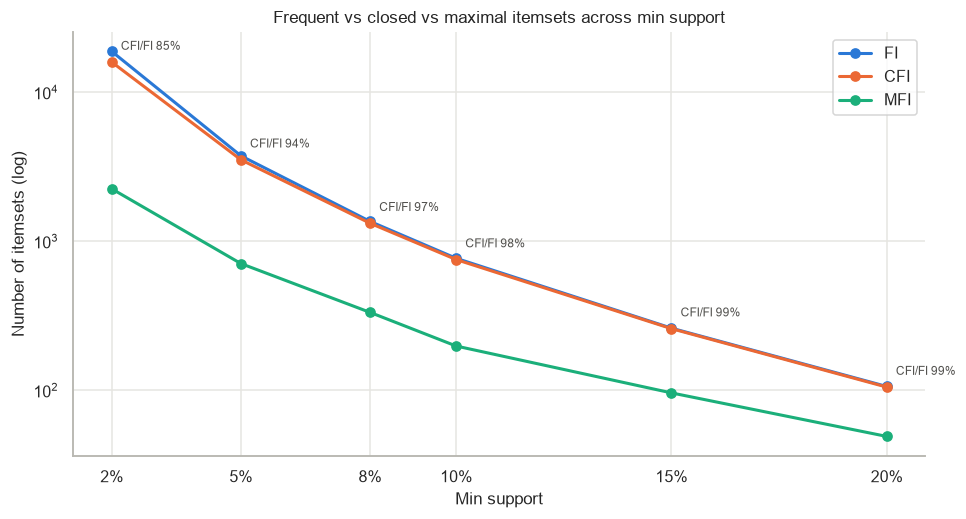

,min_sup,FI,CFI,MFI,CFI/FI,cofi_s,max_cofi_nodes
0,0.02,18770,15924,2247,0.848,1.139,4806
1,0.05,3742,3520,708,0.941,0.719,4095
2,0.08,1358,1320,333,0.972,0.186,1709
3,0.10,768,753,198,0.980,0.065,429
4,0.15,261,259,96,0.992,0.079,104
5,0.20,106,105,49,0.991,0.040,15


In [7]:
sweep = []
for ms in [0.02, 0.05, 0.08, 0.10, 0.15, 0.20]:
    f_s, s_s, _ = cofi(T, ms)
    c_s, m_s = closed_and_maximal(f_s)
    sweep.append({'min_sup': ms, 'FI': len(f_s), 'CFI': len(c_s), 'MFI': len(m_s), 'CFI/FI': len(c_s) / len(f_s),
                  'cofi_s': s_s['time_s'], 'max_cofi_nodes': s_s['max_cofi_nodes']})
sweep = pd.DataFrame(sweep)

fig, ax = plt.subplots(figsize=(10, 5))
for col, c in [('FI', CAT[0]), ('CFI', CAT[1]), ('MFI', CAT[2])]:
    ax.plot(sweep.min_sup, sweep[col], marker='o', lw=2, color=c, label=col)
for _, r in sweep.iterrows():
    ax.annotate(f"CFI/FI {r['CFI/FI']:.0%}", (r.min_sup, r.CFI), textcoords='offset points', xytext=(6, 8), fontsize=8, color='#52514e')
ax.set_yscale('log'); ax.set_xticks(sweep.min_sup, [f'{v:.0%}' for v in sweep.min_sup])
ax.set(title='Frequent vs closed vs maximal itemsets across min support', xlabel='Min support', ylabel='Number of itemsets (log)')
ax.legend()
save_fig('32_fi_cfi_mfi_vs_support'); plt.show()
sweep.round(3)

**Inferences:**
- Compression grows as support falls: CFI/FI = **99 % at 20 %** but **85 % at 2 %** (15,924 of 18,770). Lower support admits long itemsets, where exact co-occurrences become common.
- MFIs are always far fewer (12–46 % of FIs), but they lose support counts.
- At 2 % support the largest COFI-tree grows to 4,806 nodes, still a fraction of the FP-tree.

## 3. Closed association rules (Min-Max bases)

In [8]:
rules_mm, gens = minmax_rules(freq, closed, N, MIN_CONF)
cl = list(closed)
def covers(A, Z):                                   # Z is an immediate closed successor of A
    return A < Z and not any(A < B < Z for B in cl)
closed_rules = [r for r in rules_mm if r['type'] == 'exact' or covers(closure(r['antecedent'], closed, freq), r['antecedent'] | r['consequent'])]
cr = pd.DataFrame(closed_rules)
cr['lift'] = cr.confidence / cr.consequent.map(lambda s: freq[s] / N)
cr['rule'] = cr.antecedent.map(fmt) + '  →  ' + cr.consequent.map(fmt)
cr = cr.sort_values(['type', 'lift'], ascending=[True, False]).reset_index(drop=True)
cr[['type', 'rule', 'support', 'confidence', 'lift']].to_csv(OUTPUTS / 'cofi_closed_rules.csv', index=False)
print(f'Minimal generators: {len(gens)} | Min-Max rules: {len(rules_mm)} -> transitively reduced: {len(cr)}', cr.type.value_counts().to_dict())
print('\nExact closed rules (confidence 100 %):')
cr[cr.type == 'exact'][['rule', 'support', 'confidence']].round(3)

Minimal generators: 753 | Min-Max rules: 1725 -> transitively reduced: 1126 {'approximate': 1111, 'exact': 15}

Exact closed rules (confidence 100 %):


,rule,support,confidence
1111,"{Evening, Z1=High, Z2=High, Z3=High} → {Total=High}",0.142,1.0
1112,"{Evening, Workday, Z1=High, Z2=High, Z3=High} → {Total=High}",0.103,1.0
1113,"{Summer, Z1=High, Z2=High, Z3=High} → {Total=High}",0.117,1.0
1114,"{Summer, Temp=High, Z1=High, Z2=High, Z3=High} → {Total=High}",0.103,1.0
1115,"{Hum=High, Z1=Low, Z2=Low, Z3=Low} → {Total=Low}",0.103,1.0
1116,"{Temp=High, Z1=High, Z2=High, Z3=High} → {Total=High}",0.121,1.0
1117,"{Z1=High, Z2=High, Z3=High} → {Total=High}",0.202,1.0
1118,"{Solar=Dark, Z2=High, Z3=High} → {Total=High}",0.110,1.0
1119,"{Solar=Dark, Z1=High, Z2=High, Z3=High} → {Total=High}",0.106,1.0
1120,"{Workday, Z1=High, Z2=High, Z3=High} → {Total=High}",0.148,1.0


In [9]:
# Approximate closed rules: context -> load, strongest by lift
is_load = lambda i: i.startswith(('Z1', 'Z2', 'Z3', 'Total'))
ctx = cr[(cr.type == 'approximate') & cr.antecedent.map(lambda s: not any(is_load(i) for i in s))
         & cr.consequent.map(lambda s: any(is_load(i) for i in s))]
print('Approximate context -> load closed rules:', len(ctx))
ctx[['rule', 'support', 'confidence', 'lift']].head(12).round(3)

Approximate context -> load closed rules: 55


,rule,support,confidence,lift
222,"{Night, Temp=Low} → {Z1=Low}",0.105,0.968,2.903
223,"{Night, Solar=Dark, Temp=Low} → {Z1=Low}",0.105,0.968,2.903
299,"{Night, Temp=Low} → {Total=Low}",0.102,0.946,2.837
300,"{Night, Solar=Dark, Temp=Low} → {Total=Low}",0.102,0.946,2.837
536,"{Night, Wind=Calm} → {Z1=Low}",0.136,0.860,2.581
538,"{Night, Solar=Dark, Wind=Calm} → {Z1=Low}",0.135,0.860,2.581
541,"{Summer, Temp=High, Wind=Windy} → {Z3=High}",0.146,0.860,2.579
568,"{Night, Wind=Calm} → {Total=Low}",0.134,0.850,2.551
569,"{Night, Solar=Dark, Wind=Calm} → {Total=Low}",0.134,0.850,2.550
577,"{Evening, Workday} → {Total=High}",0.146,0.848,2.543


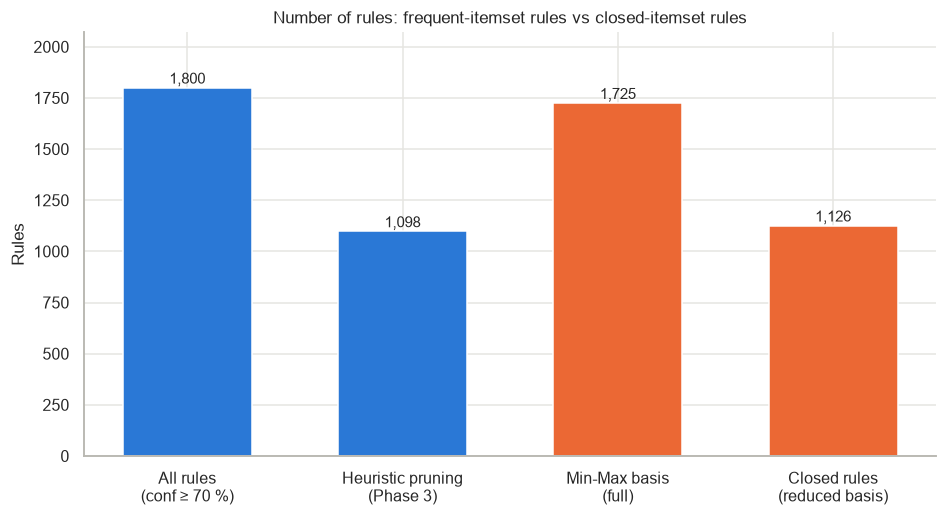

In [10]:
# Rule-set sizes: all rules vs pruned vs closed bases
dic_all = generate_rules({tuple(sorted(items.index(i) for i in k)): v for k, v in freq.items()}, N, items, MIN_CONF)
sizes_r = pd.Series({'All rules\n(conf ≥ 70 %)': len(dic_all), 'Heuristic pruning\n(Phase 3)': len(drop_redundant(dic_all)),
                     'Min-Max basis\n(full)': len(rules_mm), 'Closed rules\n(reduced basis)': len(cr)})
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(sizes_r.index, sizes_r.values, color=[CAT[0], CAT[0], CAT[1], CAT[1]], width=0.6)
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 20, f'{int(b.get_height()):,}', ha='center', fontsize=10)
ax.set(title='Number of rules: frequent-itemset rules vs closed-itemset rules', ylabel='Rules', ylim=(0, sizes_r.max() * 1.15))
save_fig('33_rule_set_sizes'); plt.show()

In [11]:
# Check: can every one of the 1,800 rules be recomputed from the 753 CFIs alone?
sup_cfi = lambda S: max(c for C, c in closed.items() if S <= C)        # support of any FI from its closed supersets
err = 0.0
for r in dic_all.itertuples():
    A = frozenset(items[i] for i in r.antecedent); Cq = frozenset(items[i] for i in r.consequent)
    err = max(err, abs(sup_cfi(A | Cq) / N - r.support), abs(sup_cfi(A | Cq) / sup_cfi(A) - r.confidence))
print(f'{len(dic_all)} rules recomputed from {len(closed)} CFIs -> max abs error in support/confidence = {err:.1e}')

1800 rules recomputed from 753 CFIs -> max abs error in support/confidence = 2.2e-16


**Inferences:**
- **15 exact closed rules** (confidence 100 %) — all of the form *{Z1, Z2, Z3 = level, + context} → Total = same level*, i.e. the sum identity. They are correct but obvious; they show that closed mining catches real exact dependencies.
- **1,111 approximate closed rules**; with the 15 exact ones, the reduced Min-Max basis has **1,126 rules vs 1,800** frequent-itemset rules (−37 %) — a non-redundant summary.
- **Verified here:** all 1,800 rules' support and confidence are **recomputed exactly from the 753 CFIs** (max error ≈ 1e-16). So the closed itemsets keep all rule information. In theory the full rule set can also be derived from the Min-Max basis itself; we did not implement that derivation, so we only claim the CFI-based reconstruction.
- The Phase 3 heuristic pruning (1,098 rules) is about as small, but has no such recovery guarantee.
- Strongest closed context → load rules agree with DIC: *{Night, Temp=Low} → {Total=Low}* (95 %), *{Summer, Temp=High, Wind=Windy} → {Z3=High}* (86 %), *{Evening} → {Total=High}* (84 %).
- Pairs like *{Night, Temp=Low}* and *{Night, Solar=Dark, Temp=Low}* both appear because *Night* does not imply *Solar=Dark* exactly (summer dawn after 05:00) — the generators differ.

## 4. Performance: COFI vs DIC vs Apriori
**Same starting point for all three:** the raw transaction list. COFI builds its FP-tree from it; DIC and Apriori first encode it into a bit matrix — that encoding is now **inside** their timers ("end-to-end"). Algorithm-only times are shown too. Best of 2 runs; timings vary a little between runs.

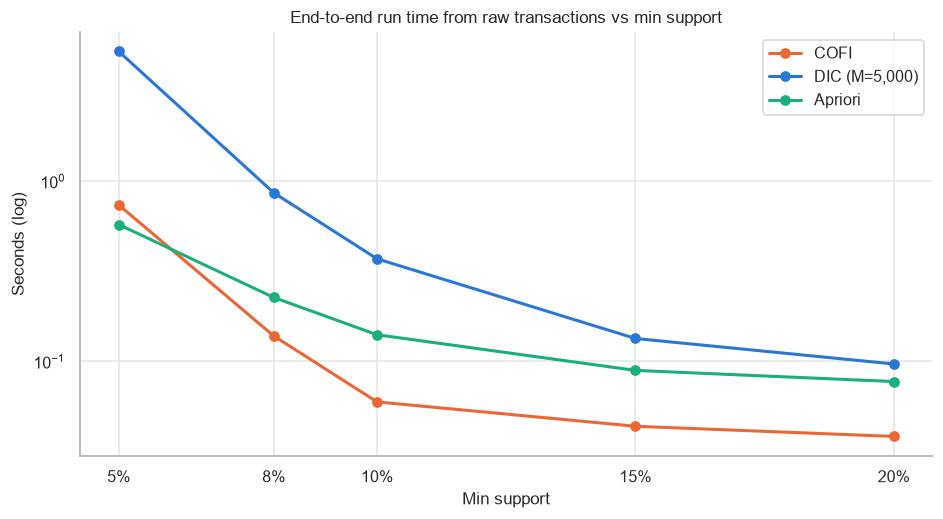

,COFI,"DIC (M=5,000)",Apriori,DIC algorithm only,Apriori algorithm only,Apriori candidates,COFI sub-patterns enumerated,FI
min_sup,,,,,,,,
0.05,0.738,5.247,0.575,5.237,0.526,6453,4300916,3742
0.08,0.139,0.862,0.226,0.809,0.174,2739,699308,1358
0.10,0.060,0.371,0.141,0.319,0.089,1575,118045,768
0.15,0.044,0.134,0.089,0.081,0.038,814,7825,261
0.20,0.038,0.097,0.077,0.046,0.026,618,456,106


In [12]:
def timed(f, runs=2):
    best, out = np.inf, None
    for _ in range(runs):
        t0 = time.perf_counter(); out = f(); best = min(best, time.perf_counter() - t0)
    return out, best

def dic_e2e(ms):
    Xe, _ = encode(T); return dic(Xe, ms, 5000)[2]
def apriori_e2e(ms):
    Xe, _ = encode(T); return apriori_counts(Xe, ms)[1]

perf = []
for ms in [0.05, 0.08, 0.10, 0.15, 0.20]:
    (_, s_c, _), t_c = timed(lambda: cofi(T, ms))
    s_d, t_d = timed(lambda: dic_e2e(ms))
    s_a, t_a = timed(lambda: apriori_e2e(ms))
    perf.append({'min_sup': ms, 'COFI': t_c, 'DIC (M=5,000)': t_d, 'Apriori': t_a,
                 'DIC algorithm only': s_d['time_s'], 'Apriori algorithm only': s_a['time_s'],
                 'Apriori candidates': s_a['itemsets_counted'], 'COFI sub-patterns enumerated': s_c['subpatterns_enumerated'],
                 'FI': s_c['frequent']})
perf = pd.DataFrame(perf).set_index('min_sup')
perf.to_csv(OUTPUTS / 'cofi_performance.csv')

fig, ax = plt.subplots(figsize=(10, 5))
for col, c in [('COFI', CAT[1]), ('DIC (M=5,000)', CAT[0]), ('Apriori', CAT[2])]:
    ax.plot(perf.index, perf[col], marker='o', lw=2, color=c, label=col)
ax.set_yscale('log'); ax.set_xticks(perf.index, [f'{v:.0%}' for v in perf.index])
ax.set(title='End-to-end run time from raw transactions vs min support', xlabel='Min support', ylabel='Seconds (log)')
ax.legend()
save_fig('34_cofi_dic_apriori_runtime'); plt.show()
perf.round(3)

**Inferences (all three timed from the raw transactions; best of 2 runs):**
- **DIC is the slowest** at every support ≤ 10 % (e.g. 0.37 s vs 0.06 s for COFI at 10 %; 5.2 s vs 0.74 s at 5 %).
- **COFI vs Apriori depends on support:** COFI is faster at 8–20 % (0.06 s vs 0.14 s at 10 %, about 2× at 15–20 %); Apriori is faster at 5 % (0.57 s vs 0.74 s). Part of COFI's lead is merging the 52 k rows into 3,986 distinct transactions first. Encoding the bit matrix (≈ 0.05 s) is part of Apriori's and DIC's cost here.
- **COFI does not avoid candidates.** It enumerates every sub-pattern of every COFI branch: **118,045 at 10 % (4.3 M at 5 %) vs 1,575 (6,453) Apriori candidates**. What it avoids is a **global candidate set and repeated data scans**: its candidates are counted from a small per-item tree (≤ 429 nodes at 10 %) that is then discarded, and the raw data is read once instead of 6–7 times. The fast-growing sub-pattern count is why COFI loses ground at low support.
- COFI's design pays off when scans are expensive (disk / distributed data) and when the per-item work runs in parallel — tested in Phase 6.

## 5. Summary

| Aspect | Result |
|---|---|
| Parameters | min support 10 %, min confidence 70 % (same as DIC) |
| Frequent itemsets | 768, identical to Apriori / DIC; raw data read once; largest COFI-tree 429 nodes (3 % of FP-tree) |
| Closed / maximal | 753 CFI (98 %, all FI supports recoverable; table in `cofi_closed_itemsets.csv`) · 198 MFI (26 %) |
| Why little compression | only exact dependency is Z1+Z2+Z3 = Total; CFI/FI falls to 85 % at 2 % support |
| Closed rules | 15 exact + 1,111 approximate = 1,126 Min-Max rules (−37 % vs 1,800); all 1,800 rules recomputed exactly from the CFIs |
| Key rules | cold Night → Low (95 %); hot windy Summer → Zone 3 High (86 %); Evening → High (84 %) |
| Performance | end-to-end from raw transactions: DIC slowest; COFI faster than Apriori at 8–20 %, slower at 5 %. COFI enumerates far more local sub-patterns (118 k at 10 %) than Apriori's candidates (1.6 k) — its gain is one raw-data scan and no global candidate set |